<a href="https://colab.research.google.com/github/SilviaVenturini/customer-segmentation-targeted-marketing/blob/main/Customer_segmentation_for_targeted_marketing_campaigns.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

CSV_URL = "https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_card_customers.csv"

df = pd.read_csv(CSV_URL)
df.shape # Check the number of rows and columns in the dataset.

(8950, 18)

In [ ]:
# Check the data type of each variable.
print("Information about the dataset:")
df.info()

Information about the dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8950 entries, 0 to 8949
Data columns (total 18 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   CUST_ID                           8950 non-null   object 
 1   BALANCE                           8950 non-null   float64
 2   BALANCE_FREQUENCY                 8950 non-null   float64
 3   PURCHASES                         8950 non-null   float64
 4   ONEOFF_PURCHASES                  8950 non-null   float64
 5   INSTALLMENTS_PURCHASES            8950 non-null   float64
 6   CASH_ADVANCE                      8950 non-null   float64
 7   PURCHASES_FREQUENCY               8950 non-null   float64
 8   ONEOFF_PURCHASES_FREQUENCY        8950 non-null   float64
 9   PURCHASES_INSTALLMENTS_FREQUENCY  8950 non-null   float64
 10  CASH_ADVANCE_FREQUENCY            8950 non-null   float64
 11  CASH_ADVANCE_TRX                  8950

In [ ]:
# Remove the CUST_ID column
df = df.drop("CUST_ID", axis=1)
df.shape

(8950, 17)

In [ ]:
# Check descriptive statistics.
print("Descriptive statistics:")
df.describe()

Descriptive statistics:


,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8950.000000,8949.000000,8950.000000,8637.000000,8950.000000,8950.000000
mean,1564.474828,0.877271,1003.204834,592.437371,411.067645,978.871112,0.490351,0.202458,0.364437,0.135144,3.248827,14.709832,4494.449450,1733.143852,864.206542,0.153715,11.517318
std,2081.531879,0.236904,2136.634782,1659.887917,904.338115,2097.163877,0.401371,0.298336,0.397448,0.200121,6.824647,24.857649,3638.815725,2895.063757,2372.446607,0.292499,1.338331
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,50.000000,0.000000,0.019163,0.000000,6.000000
25%,128.281915,0.888889,39.635000,0.000000,0.000000,0.000000,0.083333,0.000000,0.000000,0.000000,0.000000,1.000000,1600.000000,383.276166,169.123707,0.000000,12.000000
50%,873.385231,1.000000,361.280000,38.000000,89.000000,0.000000,0.500000,0.083333,0.166667,0.000000,0.000000,7.000000,3000.000000,856.901546,312.343947,0.000000,12.000000
75%,2054.140036,1.000000,1110.130000,577.405000,468.637500,1113.821139,0.916667,0.300000,0.750000,0.222222,4.000000,17.000000,6500.000000,1901.134317,825.485459,0.142857,12.000000
max,19043.138560,1.000000,49039.570000,40761.250000,22500.000000,47137.211760,1.000000,1.000000,1.000000,1.500000,123.000000,358.000000,30000.000000,50721.483360,76406.207520,1.000000,12.000000


In [ ]:
# Check how many missing values are present in each column.
print("Number of missing values for each column:")
df.isnull().sum()

Number of missing values for each column:


,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0
CASH_ADVANCE_FREQUENCY,0


In [ ]:
# Remove any columns with more than 30% missing values.
df.count()<df.shape[0]*0.7

,0
BALANCE,False
BALANCE_FREQUENCY,False
PURCHASES,False
ONEOFF_PURCHASES,False
INSTALLMENTS_PURCHASES,False
CASH_ADVANCE,False
PURCHASES_FREQUENCY,False
ONEOFF_PURCHASES_FREQUENCY,False
PURCHASES_INSTALLMENTS_FREQUENCY,False
CASH_ADVANCE_FREQUENCY,False


In [ ]:
# Remove any rows with more than 25% missing values.
row_na = df.isna().sum(axis=1)
row_na = row_na[row_na>df.shape[1]*0.25]


In [ ]:
# Replace missing values in MINIMUM_PAYMENTS with the median.
# Due to the presence of extreme outliers, the median was used as it better represents the typical customer profile without being influenced by extreme values.
df["MINIMUM_PAYMENTS"] = df["MINIMUM_PAYMENTS"].fillna(df["MINIMUM_PAYMENTS"].median())

# Replace missing values in CREDIT_LIMIT with the mean.
df["CREDIT_LIMIT"] = df["CREDIT_LIMIT"].fillna(df["CREDIT_LIMIT"].mean())

na_count = df.isnull().sum()
na_count


,0
BALANCE,0
BALANCE_FREQUENCY,0
PURCHASES,0
ONEOFF_PURCHASES,0
INSTALLMENTS_PURCHASES,0
CASH_ADVANCE,0
PURCHASES_FREQUENCY,0
ONEOFF_PURCHASES_FREQUENCY,0
PURCHASES_INSTALLMENTS_FREQUENCY,0
CASH_ADVANCE_FREQUENCY,0


In [ ]:
# Analyze skewness before standardization; highly skewed features may require log transformation to improve clustering performance.
skew_values = df.skew()
skew_initial_df = skew_values.sort_values(ascending=False).reset_index()
skew_initial_df.columns = ["variable", "skewness"]
print("--- Skewness BEFORE applying the logarithm transformation. ---")
print(skew_initial_df)

--- Skewness BEFORE applying the logarithm transformation. ---
                            variable   skewness
0                   MINIMUM_PAYMENTS  13.852446
1                   ONEOFF_PURCHASES  10.045083
2                          PURCHASES   8.144269
3             INSTALLMENTS_PURCHASES   7.299120
4                           PAYMENTS   5.907620
5                   CASH_ADVANCE_TRX   5.721298
6                       CASH_ADVANCE   5.166609
7                      PURCHASES_TRX   4.630655
8                            BALANCE   2.393386
9                   PRC_FULL_PAYMENT   1.942820
10            CASH_ADVANCE_FREQUENCY   1.828686
11        ONEOFF_PURCHASES_FREQUENCY   1.535613
12                      CREDIT_LIMIT   1.522549
13  PURCHASES_INSTALLMENTS_FREQUENCY   0.509201
14               PURCHASES_FREQUENCY   0.060164
15                 BALANCE_FREQUENCY  -2.023266
16                            TENURE  -2.943017


In [ ]:
# Apply "np.log1p" to highly skewed features to reduce outlier effects and improve K-Means clustering.
# Use log1p to handle zero values safetly.
cols_log = [
    "MINIMUM_PAYMENTS", "ONEOFF_PURCHASES", "PURCHASES",
    "INSTALLMENTS_PURCHASES","PAYMENTS", "CASH_ADVANCE_TRX",
    "CASH_ADVANCE", "PURCHASES_TRX", "BALANCE", "CREDIT_LIMIT"
]

for col in cols_log:
    df[col] = np.log1p(df[col])

# Calculate and display the skewness after the transformation.
skew_final_df = df[cols_log].skew().sort_values(ascending=False).reset_index()
skew_final_df.columns = ["variable", "skewness"]
print("--- Skewness AFTER applying the logarithm transformation. ---")
print(skew_final_df)

--- Skewness AFTER applying the logarithm transformation. ---
                 variable  skewness
0        CASH_ADVANCE_TRX  0.940131
1        MINIMUM_PAYMENTS  0.269703
2            CASH_ADVANCE  0.262594
3        ONEOFF_PURCHASES  0.185854
4           PURCHASES_TRX  0.032697
5  INSTALLMENTS_PURCHASES -0.024981
6            CREDIT_LIMIT -0.101564
7               PURCHASES -0.764492
8                 BALANCE -0.861021
9                PAYMENTS -1.778312


In [ ]:
from sklearn.preprocessing import StandardScaler
# Initialize the StandardScaler.
scaler = StandardScaler()

# Standardize the entire numerical DataFrame.
scaled_features = scaler.fit_transform(df)
df_scaled = pd.DataFrame(scaled_features, columns=df.columns)

In [ ]:
# Verify that the standardization process was carried out correctly.
display(df_scaled.describe().round(2))

,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
count,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00,8950.00
mean,0.00,0.00,0.00,0.00,-0.00,0.00,-0.00,-0.00,0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-3.06,-3.70,-1.68,-0.99,-1.09,-0.93,-1.22,-0.68,-0.92,-0.68,-0.81,-1.38,-5.08,-4.16,-5.04,-0.53,-4.12
25%,-0.65,0.05,-0.41,-0.99,-1.09,-0.93,-1.01,-0.68,-0.92,-0.68,-0.81,-0.87,-0.87,-0.42,-0.66,-0.53,0.36
50%,0.30,0.52,0.34,0.14,0.37,-0.93,0.02,-0.40,-0.50,-0.68,-0.81,0.13,-0.11,0.08,-0.14,-0.53,0.36
75%,0.73,0.52,0.72,0.97,0.91,1.04,1.06,0.33,0.97,0.44,0.78,0.72,0.84,0.58,0.65,-0.04,0.36
max,1.83,0.52,2.02,2.28,2.16,2.09,1.27,2.67,1.60,6.82,3.97,2.90,2.70,2.64,4.55,2.89,0.36


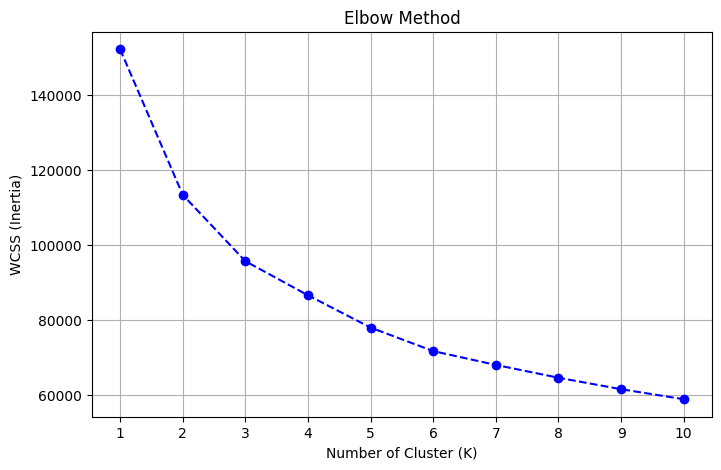

In [ ]:
from sklearn.cluster import KMeans
wcss = [] # Within-Cluster Sum of Squares
k_range = range(1, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    kmeans.fit_predict(df_scaled)
    wcss.append(kmeans.inertia_)

# Creating the Elbow Plot
plt.figure(figsize=(8, 5))
plt.plot(k_range, wcss, marker="o", linestyle="--", color="b")
plt.title("Elbow Method")
plt.xlabel("Number of Cluster (K)")
plt.ylabel("WCSS (Inertia)")
plt.xticks(k_range)
plt.grid()
plt.show()

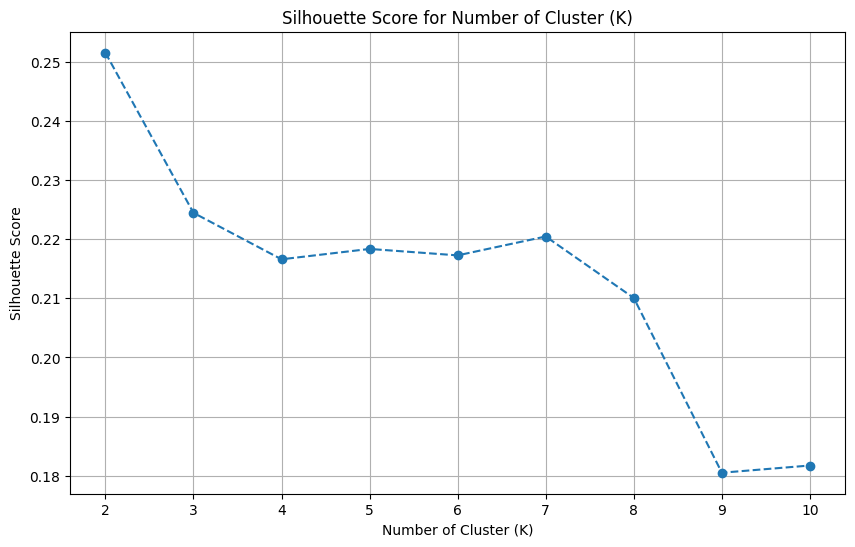

In [ ]:
from sklearn.metrics import silhouette_score

# Silhouette Score: measures clustering quality (-1 to +1); high values indicate well-separated clusters, 0 indicates overlapping clusters,
# negative values suggest possible misclassification.

silhouette_scores = []
for k in range(2, 11):
    kmeans_test = KMeans(n_clusters=k, init="k-means++", random_state=42, n_init=10)
    labels_test = kmeans_test.fit_predict(df_scaled)
    score = silhouette_score(df_scaled, labels_test)
    silhouette_scores.append(score)

# Creating the Silhouette Score Plot
plt.figure(figsize=(10, 6))
plt.plot(range(2, 11), silhouette_scores, marker='o', linestyle='--')
plt.title("Silhouette Score for Number of Cluster (K)")
plt.xlabel("Number of Cluster (K)")
plt.ylabel("Silhouette Score")
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()


In [ ]:
# Selected K=5 as the optimal number of clusters using the elbow method and the silhouette score.
# Initialize and train the model with K=5

k_optimal = 5
kmeans_train = KMeans(n_clusters=k_optimal, init="k-means++", random_state=42, n_init=10)
cluster_labels = kmeans_train.fit_predict(df_scaled)

# Add the column in the original DataFrame containing the assigned clusters
df["Cluster"] = cluster_labels

print("Distribution of Customers Across Clusters:")
print(df["Cluster"].value_counts().sort_index())

Distribution of Customers Across Clusters:
Cluster
0    1886
1    2320
2    1854
3    1498
4    1392
Name: count, dtype: int64


In [ ]:
# Analyze cluster profiles by examining average customer characteristics.
df = df.groupby("Cluster").mean()
display(df.T)

Cluster,0,1,2,3,4
BALANCE,4.907702,7.324347,6.613706,3.890577,7.764617
BALANCE_FREQUENCY,0.904742,0.935276,0.974800,0.541511,0.974803
PURCHASES,6.084985,0.832791,7.519898,4.773817,6.717252
ONEOFF_PURCHASES,0.962321,0.702334,7.017685,3.474226,5.042186
INSTALLMENTS_PURCHASES,6.011313,0.135409,5.019839,1.750423,4.614663
CASH_ADVANCE,0.433074,6.843997,0.615194,1.096455,7.347636
PURCHASES_FREQUENCY,0.806642,0.022831,0.839049,0.219501,0.668055
ONEOFF_PURCHASES_FREQUENCY,0.026286,0.017191,0.614774,0.113492,0.296505
PURCHASES_INSTALLMENTS_FREQUENCY,0.762502,0.004787,0.535250,0.101910,0.479537
CASH_ADVANCE_FREQUENCY,0.009055,0.280831,0.011954,0.023349,0.347556


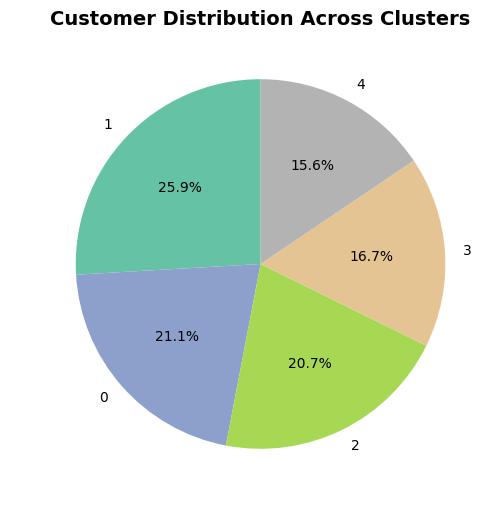

In [ ]:
# Calculate the percentage
cluster_counts = pd.Series(cluster_labels).value_counts(normalize=True) * 100

# Pie Chart
plt.figure(figsize=(8, 6))
cluster_counts.plot(kind="pie", autopct="%1.1f%%", startangle=90, cmap="Set2")
plt.title("Customer Distribution Across Clusters", fontsize=14, fontweight="bold")
plt.ylabel(" ")
plt.show()

### Detailed analysis and marketing strategies for clusters

By analyzing the average characteristics of each cluster, we can define more precise profiles and develop targeted marketing strategies.

---

#### **Cluster 0: "Pure Installment Users"**

*    **Profile**: They prefer to use the card exclusively for installment purchases (6.01)instead of one-time purchases (0.96). They use their credit card frequently (PURCHASES_FREQUENCY = 0.80) and never withdraw cash. The high percentage of balances paid in full (PRC_FULL_PAYMENT = 0.30) shows that these customers are good at managing their payment deadlines.

*   **Marketing Strategy**: They are stable and reliable customers who plan their monthly budget through financing.
    *   **Action**: Instant installment options directly from the bank’s app and offer zero-interest financing
   
#### **Cluster 1: “Cash Borrowers”**

*    **Profile**: They use the card only and exclusively to withdraw cash at ATMs (CASH_ADVANCE = 6.84). They do not shop in stores often and, in fact, have the lowest value in the entire dataset (PURCHASES = 0.83).They make very few single payments and almost never pay off the entire balance (PRC_FULL_PAYMENT = 0.03, the absolute minimum).

*   **Marketing Strategy**: They use their credit cards as if they were ATM cards to get immediate cash, generating significant revenue for the bank through withdrawal commissions and interest on uncovered balances.
    *   **Action**: Offer flexible personal loans with fixed installments to reduce the risk of default and structure a debt repayment plan.

#### **Cluster 2: “Top Spenders / VIP Customers”**

*    **Profile**: These customers are the most valuable in terms of revenue generation. They use their credit cards very frequently (BALANCE_FREQUENCY = 0.97) and exhibit a high purchase volume. They are inclined toward both one-time purchases (7.01) and installment payments (5.01), indicating active and diversified spending behavior. Additionally, they benefit from a significantly higher credit limit compared to other customer segments (CREDIT_LIMIT = 8.51).

*   **Marketing Strategy**: They represent a significant source of profit for both merchants and the bank itself because they generate revenue. The primary goal is customer retention to prevent them from switching to competitors.
    *   **Action**: Offer luxury services and provide access to premium or exclusive programs, such as Gold or Premium card memberships.

#### **Cluster 3: “Low-Engagement Shoppers”**

*    **Profile**: This customer segment exhibits the lowest average balance in the dataset (BALANCE = 3.89) and uses credit cards infrequently, as reflected by the low balance frequency (BALANCE_FREQUENCY = 0.54) and purchase frequency (PURCHASES_FREQUENCY = 0.21). When transactions do occur, customers show a preference for one-time purchases (3.47) rather than installment-based payments (1.75).

*   **Marketing Strategy**: They are dormient customers who use the card only for emergencies.
    *   **Action**: Encourage daily use of the card for small expenses by offering cashback or immediate discounts on essential categories, such as supermarkets or petrol.
    
#### **Cluster 4: “High-Spend Cash Consumers”**

*    **Profile**: They use their card frequently (BALANCE_FREQUENCY = 0.97) and spend a lot in stores (PURCHASES = 6.71); they mainly make one-time purchases (5.04), but at the same time they use their card to withdraw cash (CASH_ADVANCE = 7.34). They have a low percentage of balances paid in full (PRC_FULL_PAYMENT = 0.03).

*   **Marketing Strategy**: This segment combine the high spending of Cluster 2 with the strong need for immediate cash of Cluster 1. They represent a source of interest revenue, but also a potential credit risk.
    *   **Action**: Rather than aggressive spending promotions, in this case the focus should be on controlled repayment plans and installment payments, ensuring that the credit limit is not exceeded.